In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
import fspiderman as sp
import batman
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from HItargets_utils import hi_planets_by_name, filter_loc, filter_lambda, instruments, DEFAULT_A_B, DEFAULT_U_B, DEFAULT_U
from paper_plot_utils import paper_figure, paper_theme

looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("TOI-2431 b") # "K2-141 b", "TOI-2431 b"
period, incl, ecc, w, rp, r2, a, T_eff, a_AU = planet.args

u, u_B = DEFAULT_U, DEFAULT_U_B   # transit and irradiance limb darkening (baseline settings, HItargets_utils.py)

In [3]:
A_B = DEFAULT_A_B   # Bond albedo: sets the temperature map (baseline settings, HItargets_utils.py)

In [4]:
# Filter to be used
Instrument = "MIRI/LRS"
lambda_range = filter_lambda(Instrument)
filter_path = filter_loc(Instrument)

## Thermal Phasecurve from Custom Spiderman brightness map (Hyperillumination)

### Build and verify the (lo, la, T) grid from `insolation_hyperillum`

In [5]:
lo, la, temp_grid = custom_temperature_grid(planet, insolation_model = "hyperillum", u_B=u_B)

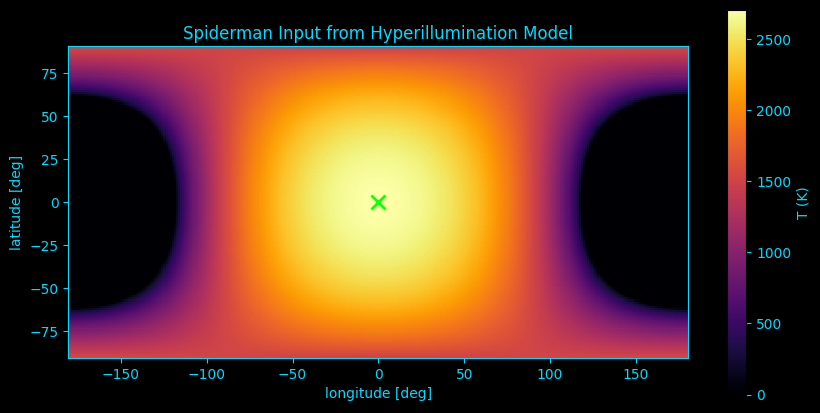

In [6]:
PAPER_MODE = False
bg, tc = ("white", "black") if PAPER_MODE else ("black", "#04d9ff")   # same dark theme as plot_insolmap(..., theme='black'); white in paper mode

fig, ax = plt.subplots(figsize=(10, 5), facecolor=bg)
im = ax.pcolormesh(lo, la, temp_grid, cmap=plt.cm.inferno, shading="auto")   # same colormap as plot_insolmap
ax.plot(0, 0, "x", color="#0cff0c", ms=10, mew=2)   # substellar point, same marker convention as spiderman's plot_square
ax.set_aspect("equal")
ax.set_facecolor(bg)
ax.set_xlabel("longitude [deg]", color=tc)
ax.set_ylabel("latitude [deg]", color=tc)
ax.tick_params(colors=tc)
for spine in ax.spines.values():
    spine.set_color(tc)

cbar = fig.colorbar(im, ax=ax)
cbar.ax.tick_params(colors=tc)
cbar.set_label("T (K)", color=tc)

ax.set_title("Spiderman Input from Hyperillumination Model", color=tc)
paper_figure(f"tempgrid_spiderman_input_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()

### SPIDERMAN phase curve from the custom brightness map (`direct_T`)

In [7]:
t_hyperillum, thermal_phasecurve_hyperillum, thermal_fp_hyperillum, spider_params_hyperillum = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="hyperillum", filter_path=filter_path, A_B=A_B, u_B=u_B)
t_naive, thermal_phasecurve_naive, thermal_fp_naive, spider_params_naive = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="naive", filter_path=filter_path, A_B=A_B, u_B=u_B)

#### Brightness Maps

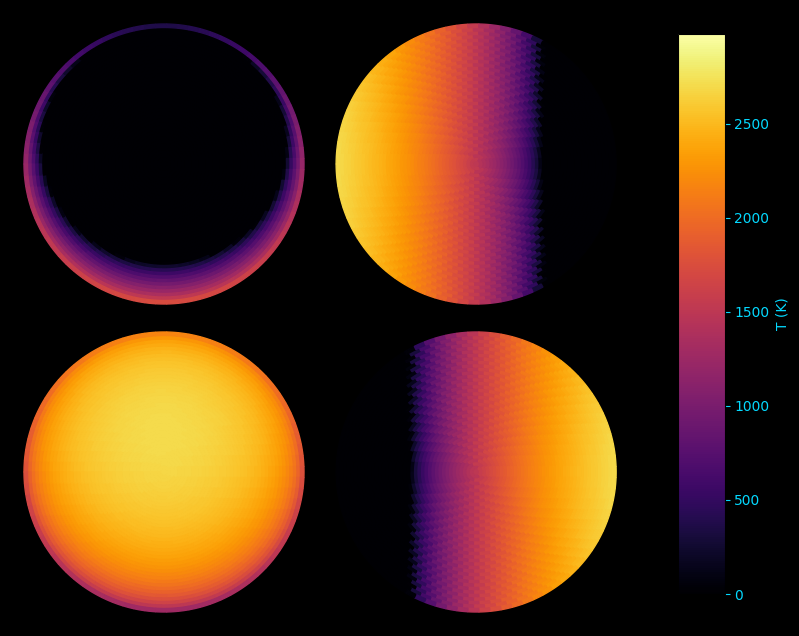

In [8]:
PAPER_MODE = False
fig = spider_params_hyperillum.plot_quad(temp_map=True, theme=paper_theme(PAPER_MODE))
paper_figure(f"tempmap_quad_spiderman_hyperillum_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig, tight=False)
plt.show()

# phase = 0.25
# spider_params_hyperillum.plot_planet(phase,use_phase=True,temp_map=True, theme='black')
# plt.show()

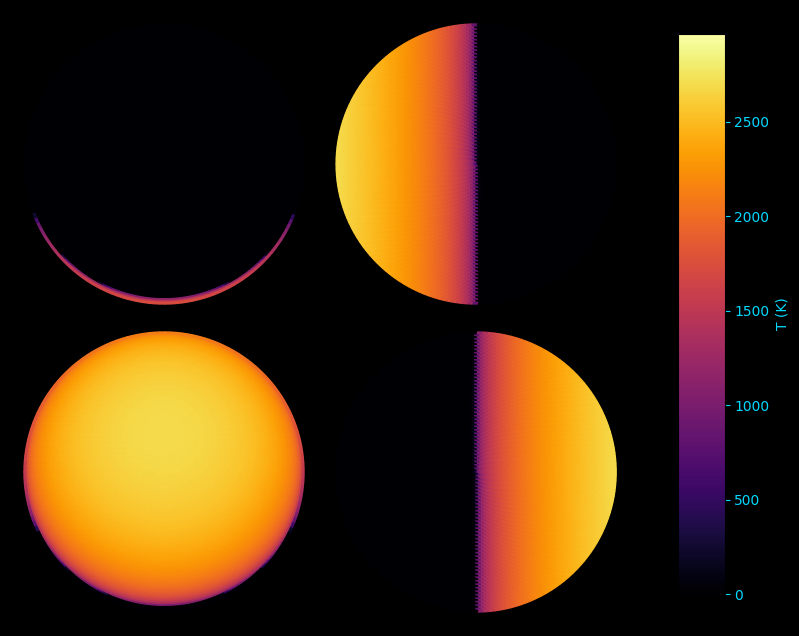

In [9]:
PAPER_MODE = False
fig = spider_params_naive.plot_quad(temp_map=True, theme=paper_theme(PAPER_MODE))
paper_figure(f"tempmap_quad_spiderman_naive_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig, tight=False)
plt.show()

# phase = 0.25
# phase_curve_naive.plot_planet(phase,use_phase=True,temp_map=True, theme='black')
# plt.show()

Slight asymmetry at phase = 0, caused by the inclination ($i = 86.3°$ (K2-141 b)).

#### Phase Curve

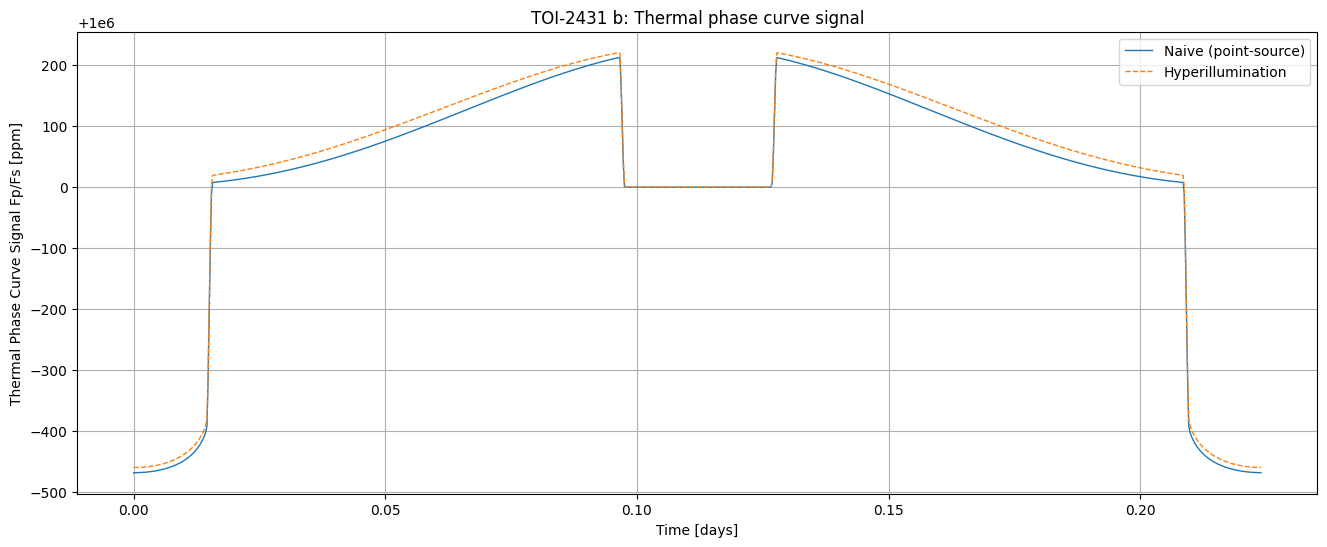

Occultation depth with Hyperillumination: 232.2 ppm
Occultation depth without Hyperillumination: 228.1 ppm


In [10]:
PAPER_MODE = False
plt.figure(figsize=(16, 6))
plt.plot(t_naive, thermal_phasecurve_naive*1e6, linewidth=1, label="Naive (point-source)")
plt.plot(t_hyperillum, thermal_phasecurve_hyperillum*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Phase Curve Signal Fp/Fs [ppm]")
plt.title(f"{planet.name}: Thermal phase curve signal")
plt.legend()
plt.grid()
paper_figure(f"thermalpc_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

print(f"Occultation depth with Hyperillumination: {thermal_fp_hyperillum:.1f} ppm")
print(f"Occultation depth without Hyperillumination: {thermal_fp_naive:.1f} ppm")

**Check against a measurement.** K2-141 b has a measured occultation depth of 142 ppm at 4.5 µm (Spitzer/IRAC2, Zieba et al. 2022). To compare with it, run this section with K2-141 b and `Instrument = "Spitzer/IRAC2"` (with MIRI/LRS the depth is that of a different band). At the baseline Bond albedo the model then lies above the measurement both with and without hyperillumination, and the two models differ by far less than that offset: the comparison tests the assumed $A_B$ and the planet radius, not hyperillumination.

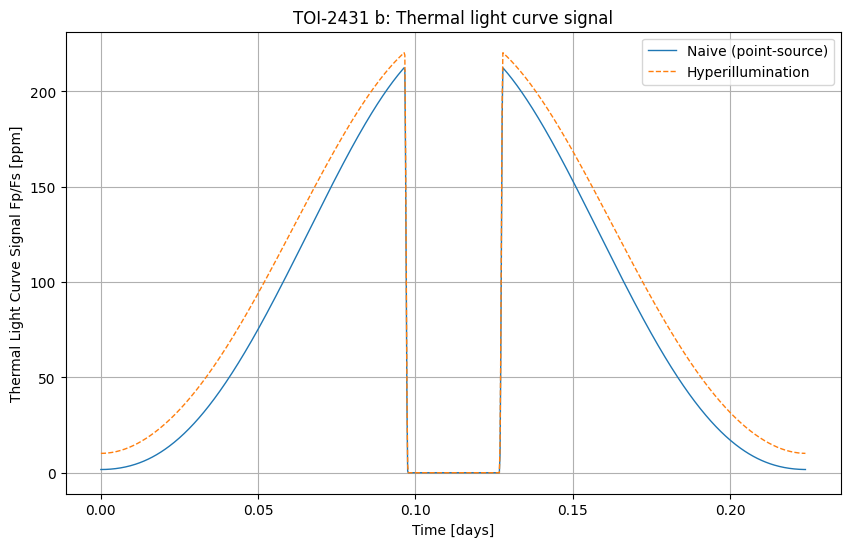

In [11]:
PAPER_MODE = False
t_hyperillum, thermal_lightcurve_hyperillum, fp_hi, _ = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="hyperillum", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=True, u_B=u_B)
t_naive, thermal_lightcurve_naive, fp_naive, _ = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="naive", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=True, u_B=u_B)

plt.figure(figsize=(10, 6))
plt.plot(t_naive, thermal_lightcurve_naive*1e6, linewidth=1, label="Naive (point-source)")
plt.plot(t_hyperillum, thermal_lightcurve_hyperillum*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title(f"{planet.name}: Thermal light curve signal")
plt.legend()
plt.grid()
paper_figure(f"thermal_lc_occ_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

In [12]:
print(f"Dayside Brightness Temperature (hyperillumination): {T_bright(fp_hi, planet, lambda_range, filter_path=filter_path):.0f} K")
print(f"Dayside Brightness Temperature (naive): {T_bright(fp_naive, planet, lambda_range, filter_path=filter_path):.0f} K")

Dayside Brightness Temperature (hyperillumination): 2375 K
Dayside Brightness Temperature (naive): 2347 K


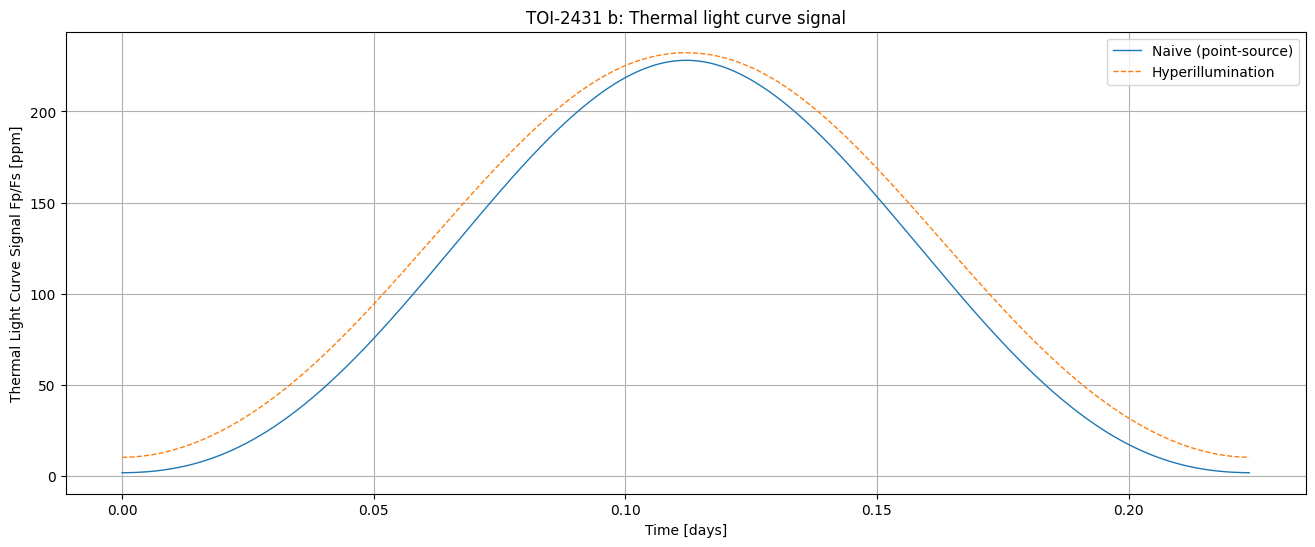

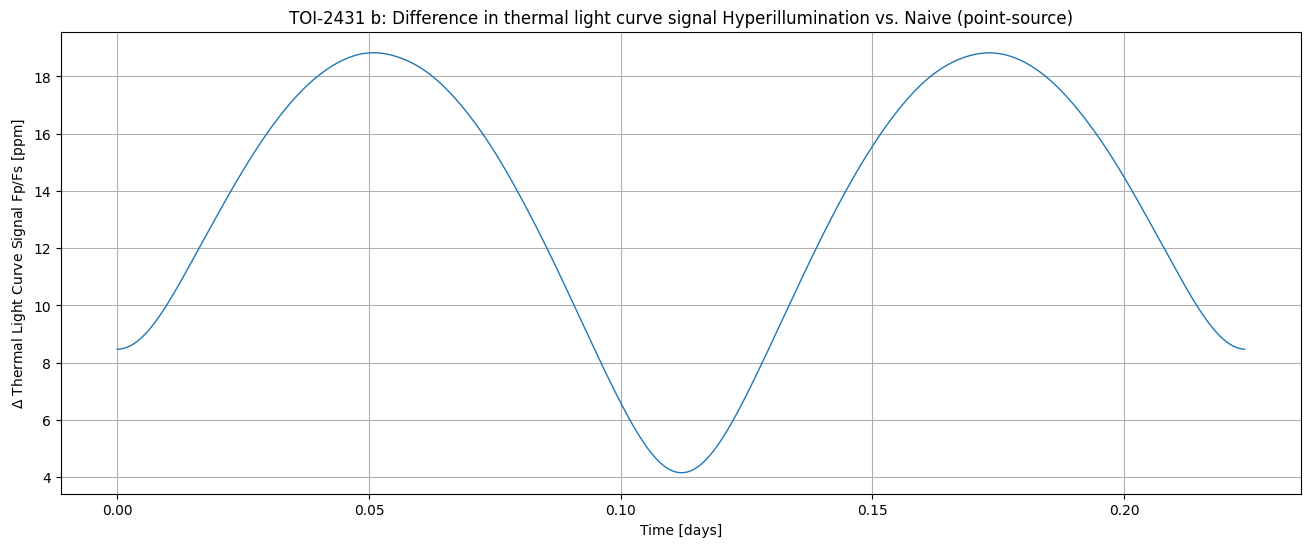

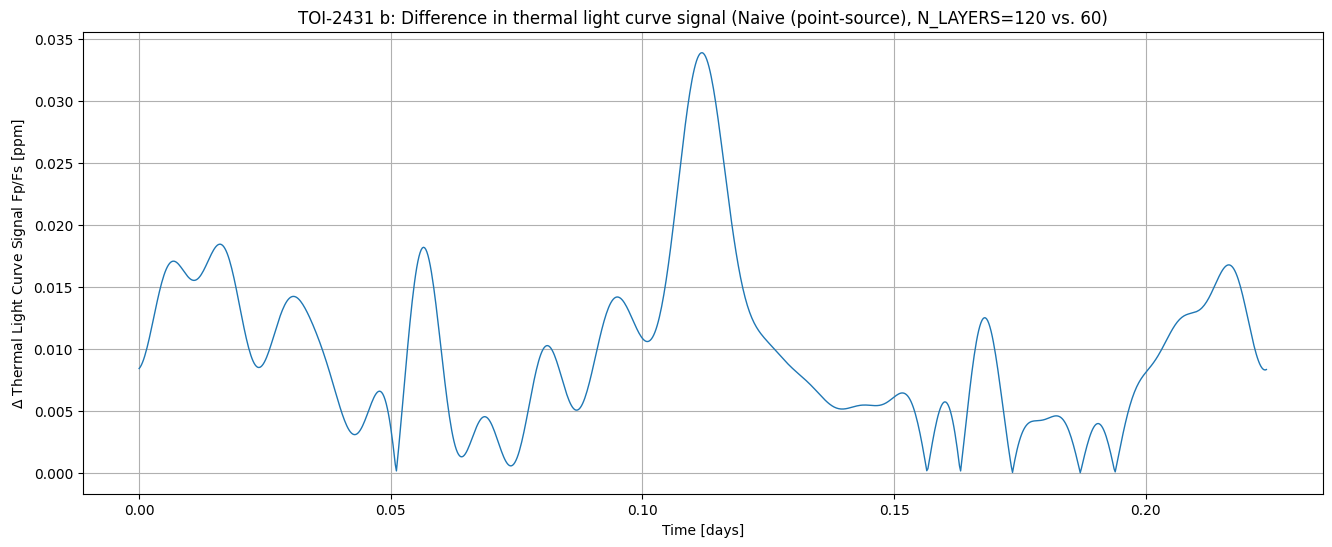

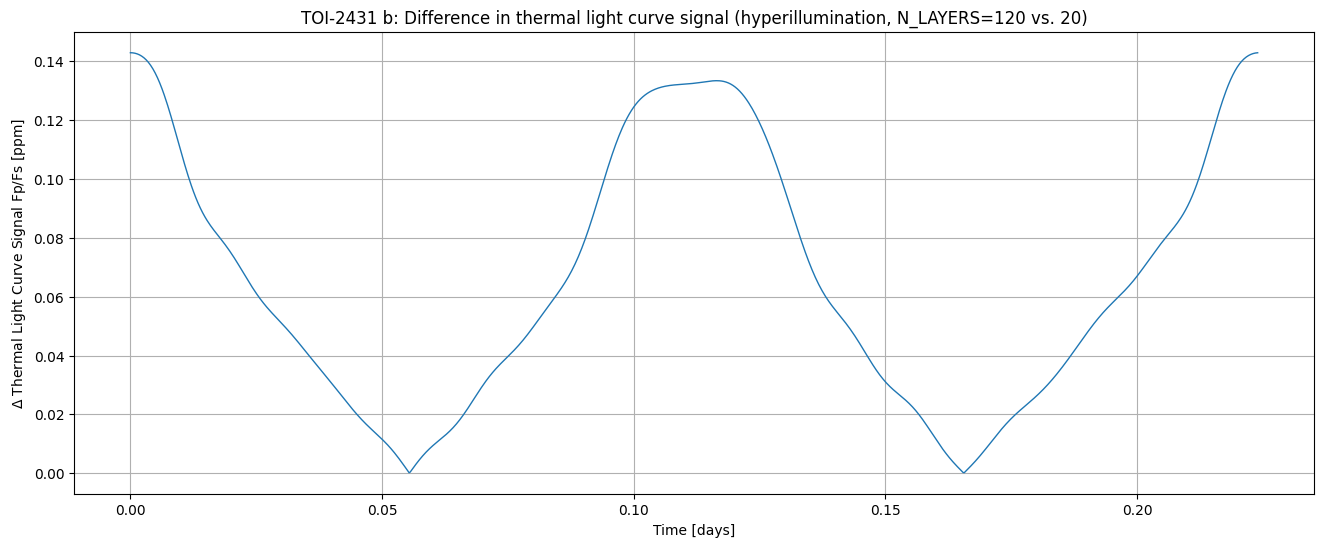

In [13]:
PAPER_MODE = False
t_hyperillum, thermal_lightcurve_hyperillum, _, _ = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="hyperillum", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=False, u_B=u_B) # N_LAYERS=40
t_naive, thermal_lightcurve_naive, _, _ = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="naive", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=False, u_B=u_B) # N_LAYERS=80
t_hyperillum, thermal_lightcurve_hyperillum_120, _, _ = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="hyperillum", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=False, N_LAYERS=120, u_B=u_B)
t_naive, thermal_lightcurve_naive_120, _, _ = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="naive", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=False, N_LAYERS=120, u_B=u_B)

plt.figure(figsize=(16, 6))
plt.plot(t_naive, thermal_lightcurve_naive * 1e6, linewidth=1, label="Naive (point-source)")
plt.plot(t_hyperillum, thermal_lightcurve_hyperillum * 1e6, linewidth=1, linestyle="--", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title(f"{planet.name}: Thermal light curve signal")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()
paper_figure(f"thermal_lc_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

plt.figure(figsize=(16, 6))
plt.plot(t_naive, (thermal_lightcurve_hyperillum - thermal_lightcurve_naive) * 1e6, linewidth=1)
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title(f"{planet.name}: Difference in thermal light curve signal Hyperillumination vs. Naive (point-source)")
#plt.ylim(0., 0.8e-7)
plt.grid()
paper_figure(f"thermal_lc_hi_minus_naive_{planet.name.replace(' ', '')}", PAPER_MODE)

plt.figure(figsize=(16, 6))
plt.plot(t_naive, np.abs((thermal_lightcurve_naive-thermal_lightcurve_naive_120))*1e6, linewidth=1)
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title(f"{planet.name}: Difference in thermal light curve signal (Naive (point-source), N_LAYERS=120 vs. 60)")
#plt.ylim(0., 0.8e-7)
plt.grid()
paper_figure(f"thermal_lc_naive_nlayers_conv_{planet.name.replace(' ', '')}", PAPER_MODE)

plt.figure(figsize=(16, 6))
plt.plot(t_naive, np.abs((thermal_lightcurve_hyperillum-thermal_lightcurve_hyperillum_120))*1e6, linewidth=1)
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title(f"{planet.name}: Difference in thermal light curve signal (hyperillumination, N_LAYERS=120 vs. 20)")
#plt.ylim(0., 0.8e-7)
plt.grid()
paper_figure(f"thermal_lc_hi_nlayers_conv_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

- Wiggles are a numerical artefact in naive light curve signal caused by truncation at 90° (Spiderman converges well only for smooth integrands). Can be fixed by setting n_layers = 120.
- Difference in occultation depth between hyperillumination and plane-parallel (naive) model no good proxi for detectability - negligible phase curve differences at alpha=0...

## Consistency Check: Compare custom Spiderman model `insolation=naive` with Spiderman Louden model `F=0`

SPIDERMAN's "Louden" brightness model implements the Kreidberg & Loeb (2016) toy heat-redistribution map with an added internal-heat term:

$$T(\phi,\lambda) = T_\mathrm{int} + \left[\frac{(1-A_B)\,S}{\sigma}\left((1-2F)\cos\phi\cos\lambda + \tfrac{F}{2}\right)\right]^{1/4},$$

on the dayside ($|\lambda| \leq \pi/2$), and $T = T_\mathrm{int} + \left[(1-A_B)\,S\,F/2\sigma\right]^{1/4}$ on the nightside, where $\phi, \lambda$ are latitude/longitude from the substellar point, $S$ the substellar insolation, and $F \in [0, 0.5]$ the redistribution parameter ($F=0$: instant reradiation, 0 K nightside; $F=0.5$: isothermal planet). It describes a bare, grey, zero-heat-capacity surface in local radiative equilibrium, and is symmetric about the substellar point by construction (no advection, hence no hotspot offset). With $F=0$ and $T_\mathrm{int}=0$ it is analytically identical to the naive plane-parallel map built here from `naive_insolation` + `BBtemp_from_insolation`, and therefore serves as an independent check on the `direct_T` pipeline.

In [14]:
t_naive, thermal_lightcurve_naive, _, _ = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="naive", filter_path=filter_path, A_B=A_B, include_transit=False, u_B=u_B)

In [15]:
t_louden, lightcurve_louden, fp_louden, _ = Louden_PhaseCurve(planet, lambda_range, u=u, filter_path=filter_path, A_B=A_B, include_transit=False)

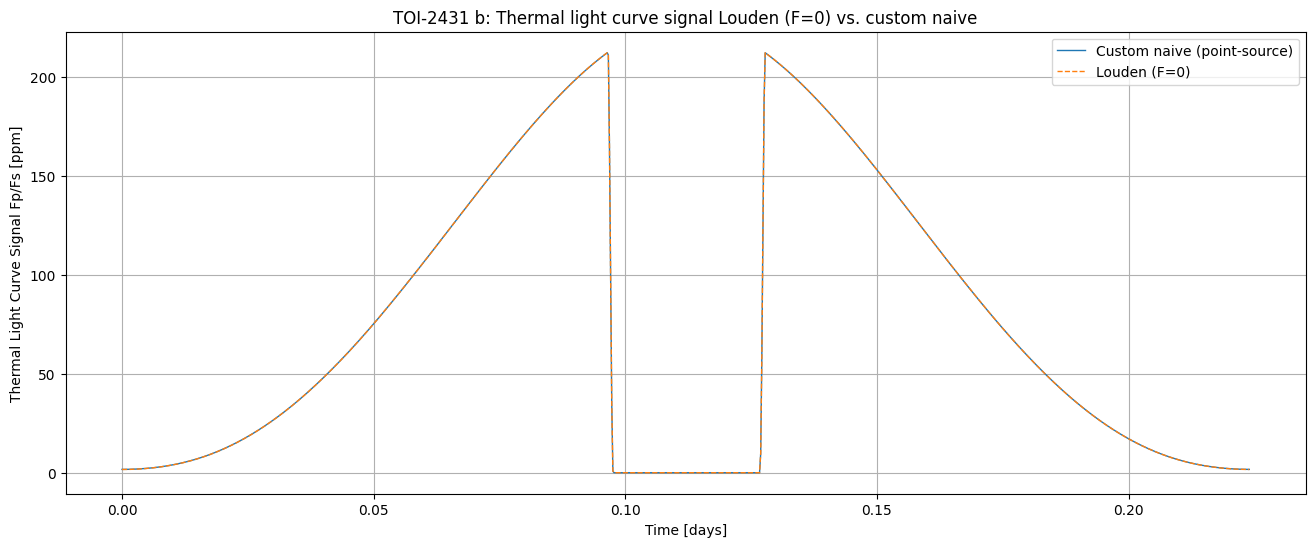

Occultation depth Louden (F=0): 228.1 ppm
Occultation depth custom naive: 228.1 ppm


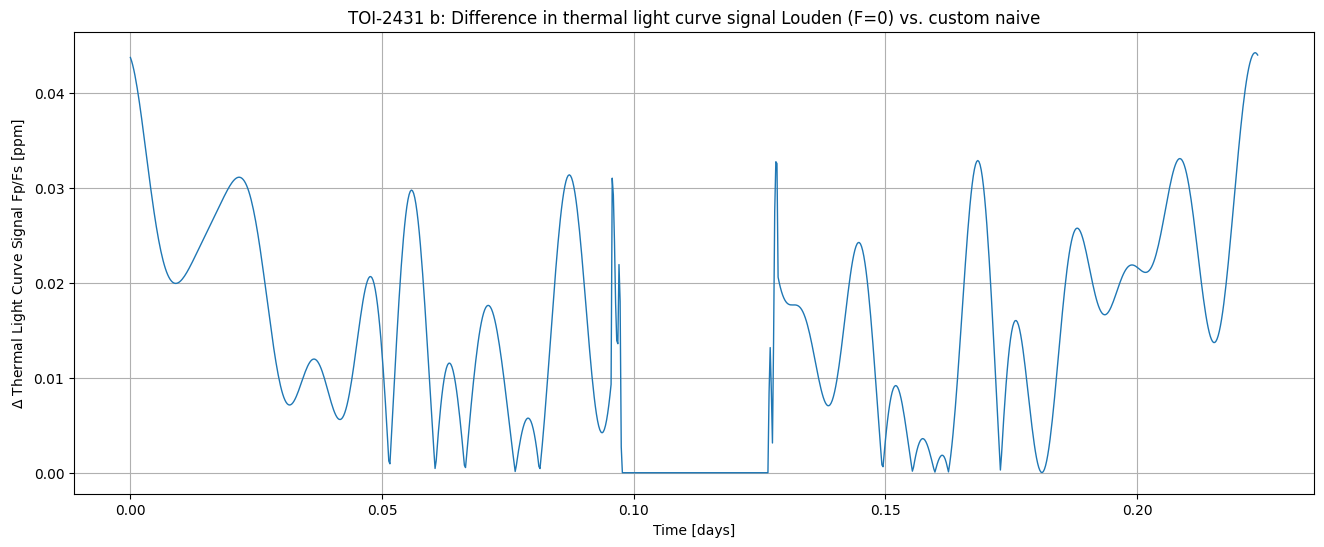

In [16]:
PAPER_MODE = False
plt.figure(figsize=(16, 6))
plt.plot(t_naive, thermal_lightcurve_naive*1e6, linewidth=1, label="Custom naive (point-source)")
plt.plot(t_naive, lightcurve_louden*1e6, linewidth=1, linestyle="--", label="Louden (F=0)")
plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title(f"{planet.name}: Thermal light curve signal Louden (F=0) vs. custom naive")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()
paper_figure(f"thermal_louden_vs_naive_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

plt.figure(figsize=(16, 6))
plt.plot(t_naive, np.abs((lightcurve_louden-thermal_lightcurve_naive))*1e6, linewidth=1)
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title(f"{planet.name}: Difference in thermal light curve signal Louden (F=0) vs. custom naive")
#plt.ylim(0., 0.8e-7)
plt.grid()
paper_figure(f"thermal_louden_vs_naive_diff_{planet.name.replace(' ', '')}", PAPER_MODE)

print(f"Occultation depth Louden (F=0): {fp_louden:.1f} ppm")
print(f"Occultation depth custom naive: {thermal_fp_naive:.1f} ppm")

## Parameter Sweep

#### Sweep 1: Bond albedo $A_B$

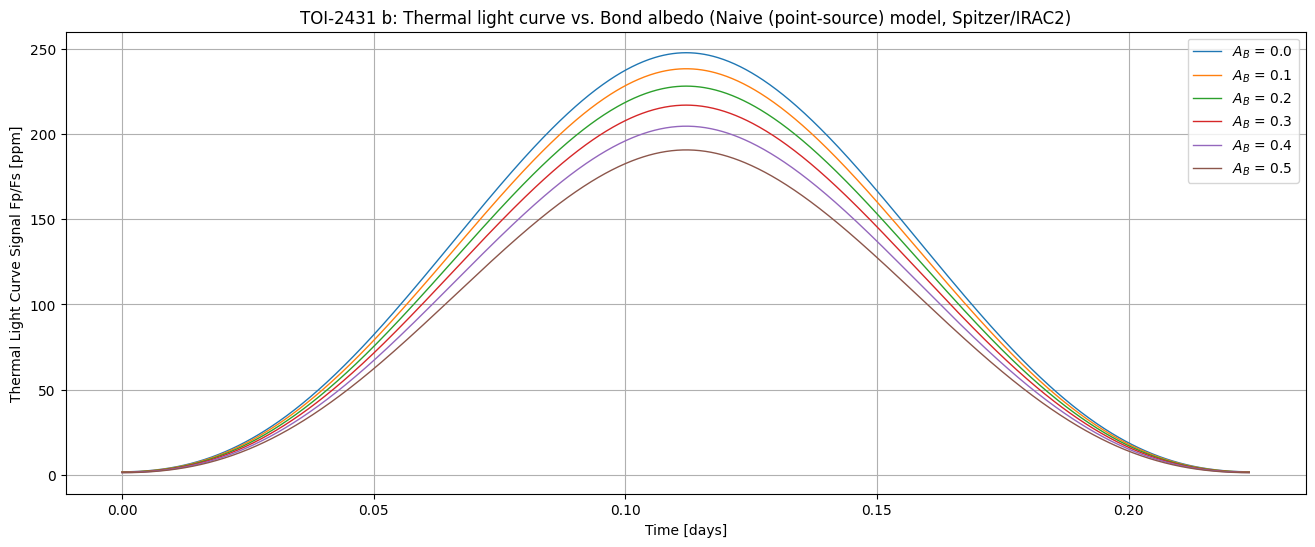

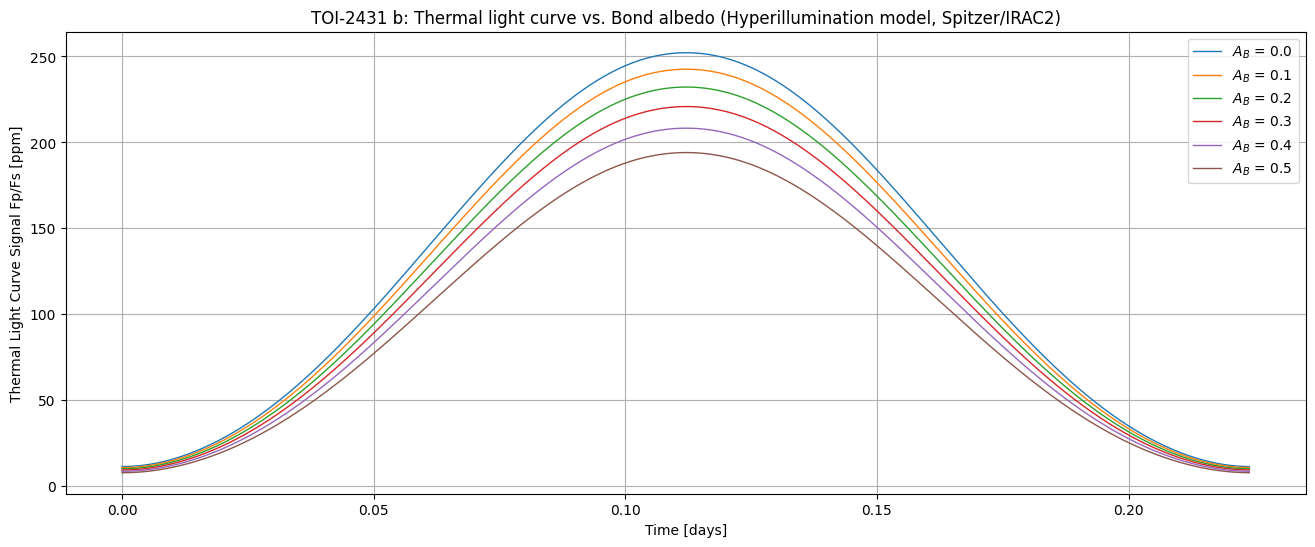

In [17]:
PAPER_MODE = False
A_B_sweep = np.arange(0.0, 0.51, 0.1)  # 0.0, 0.1, ..., 0.5

for insolation_model, label in [("naive", "Naive (point-source)"), ("hyperillum", "Hyperillumination")]:
    plt.figure(figsize=(16, 6))
    for A_B_val in A_B_sweep:
        t_sw, lc_sw, _, _ = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model=insolation_model, filter_path=filter_path, A_B=A_B_val, include_transit=False, include_occultation=False, u_B=u_B)
        plt.plot(t_sw, lc_sw*1e6, linewidth=1, label=f"$A_B$ = {A_B_val:.1f}")
    plt.xlabel("Time [days]")
    plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
    plt.title(f"{planet.name}: Thermal light curve vs. Bond albedo ({label} model, Spitzer/IRAC2)")
    plt.legend()
    plt.grid()
    paper_figure(f"thermal_lc_vs_AB_{insolation_model}_{planet.name.replace(' ', '')}", PAPER_MODE)
    plt.show()

#### Sweep 2: Wavelength range

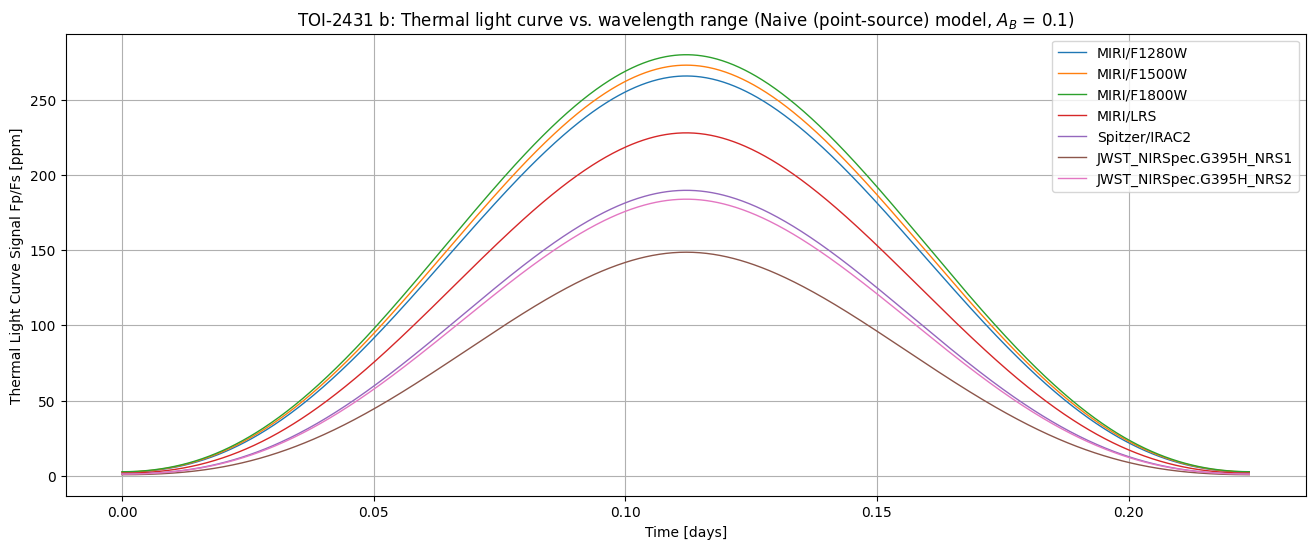

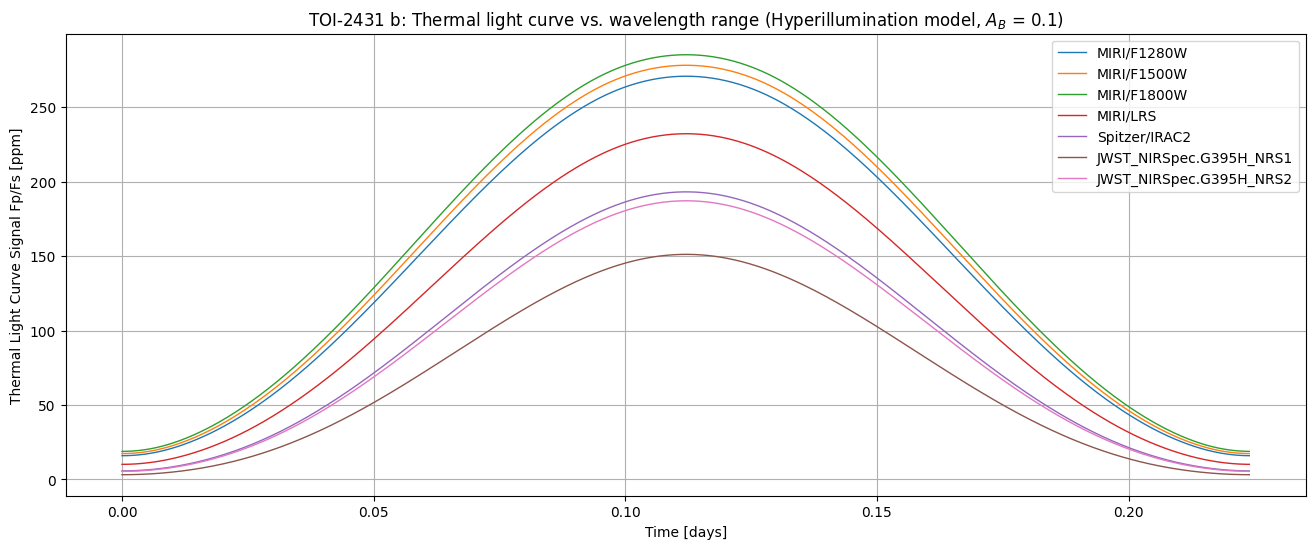

In [18]:
PAPER_MODE = False
for insolation_model, label in [("naive", "Naive (point-source)"), ("hyperillum", "Hyperillumination")]:
    plt.figure(figsize=(16, 6))
    for band_name in instruments():
        lambda_range_sw = filter_lambda(band_name)
        filter_path_sw = filter_loc(band_name)
        t_sw, lc_sw, _, _ = thermal_PhaseCurve(planet, lambda_range_sw, u=u, insolation_model=insolation_model, filter_path=filter_path_sw, A_B=A_B, include_transit=False, include_occultation=False, u_B=u_B)
        plt.plot(t_sw, lc_sw*1e6, linewidth=1, label=band_name)
    plt.xlabel("Time [days]")
    plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
    plt.title(f"{planet.name}: Thermal light curve vs. wavelength range ({label} model, $A_B$ = 0.1)")
    plt.legend()
    plt.grid()
    paper_figure(f"thermal_lc_vs_band_{insolation_model}_{planet.name.replace(' ', '')}", PAPER_MODE)
    plt.show()

## Difference between hyperillumination and naive model 

Ceteris paribus sweeps: for each parameter, all other parameters are held at the K2-141b baseline values set at the top of this notebook (`period, incl, ecc, w, rp, a, T_eff, u, A_B, lambda_range, filter_path`), and only the swept parameter is varied. Each plot shows the Hyperillumination - Naive difference in the thermal light curve signal.

In [19]:
PAPER_MODE = False
from dataclasses import replace

PLANET_FIELDS = {"period", "incl", "ecc", "w", "r1", "r2", "R", "T2_eff", "a_AU"}

# baseline non-swept thermal_PhaseCurve kwargs (the planet is held at planet)
baseline_kwargs = dict(lambda_range=lambda_range, filter_path=filter_path, u=u, u_B=u_B, A_B=A_B)

def sweep_hyperillumination_minus_naive(param_name, values, label_fmt, title_suffix, planet=planet, **base_kwargs):
    plt.figure(figsize=(16, 6))
    for val in values:
        p = replace(planet, **{param_name: val}) if param_name in PLANET_FIELDS else planet
        kwargs = dict(base_kwargs)
        if param_name not in PLANET_FIELDS: kwargs[param_name] = val
        t_k, lc_k, _, _ = thermal_PhaseCurve(p, insolation_model="hyperillum", include_transit=False, include_occultation=False, **kwargs)
        _,   lc_n, _, _ = thermal_PhaseCurve(p, insolation_model="naive", include_transit=False, include_occultation=False, **kwargs)
        if param_name=="period": plt.plot(t_k/val, (lc_k - lc_n)*1e6, linewidth=1, label=label_fmt(val))
        else: plt.plot(t_k, (lc_k - lc_n)*1e6, linewidth=1, label=label_fmt(val))
    if param_name=="period": plt.xlabel("Orbital Phase")
    else: plt.xlabel("Time [days]")
    plt.ylabel(r"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm] (Hyperillumination $-$ Naive)")
    plt.title(f"{planet.name}: Hyperillumination $-$ Naive vs. {title_suffix}")
    plt.legend()
    plt.grid()
    paper_figure(f"thermal_hi_minus_naive_vs_{param_name}_{planet.name.replace(' ', '')}", PAPER_MODE)   # PAPER_MODE of the calling cell
    plt.show()

#### Bond albedo $A_B$

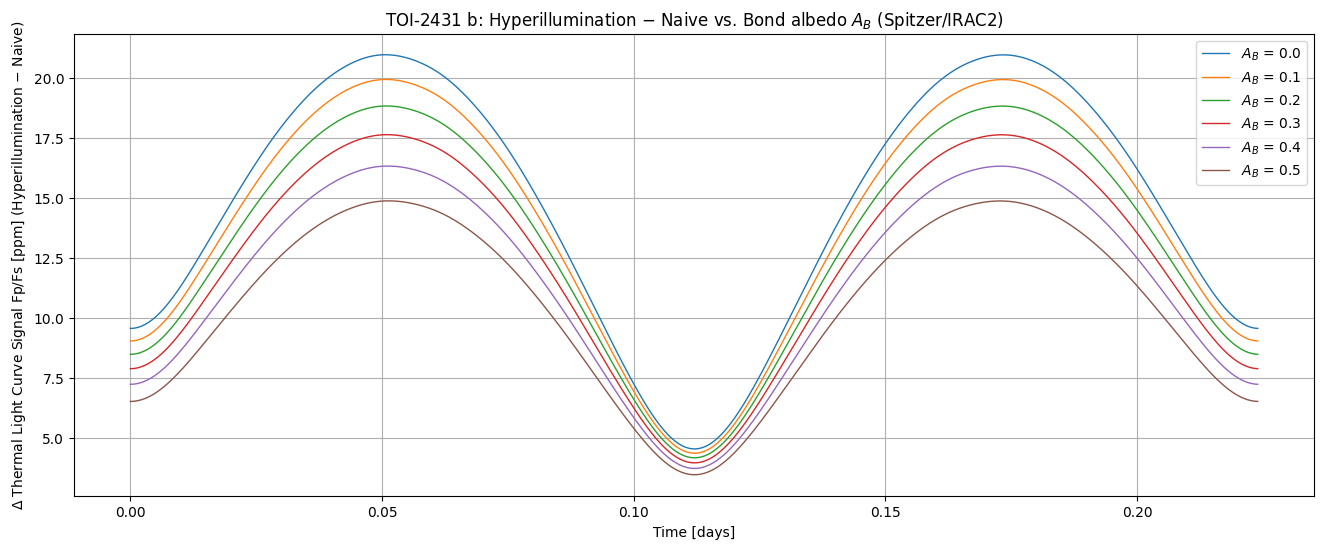

In [20]:
PAPER_MODE = False
sweep_hyperillumination_minus_naive("A_B", np.arange(0.0, 0.51, 0.1), lambda v: f"$A_B$ = {v:.1f}", "Bond albedo $A_B$ (Spitzer/IRAC2)", **baseline_kwargs)

#### Wavelength range

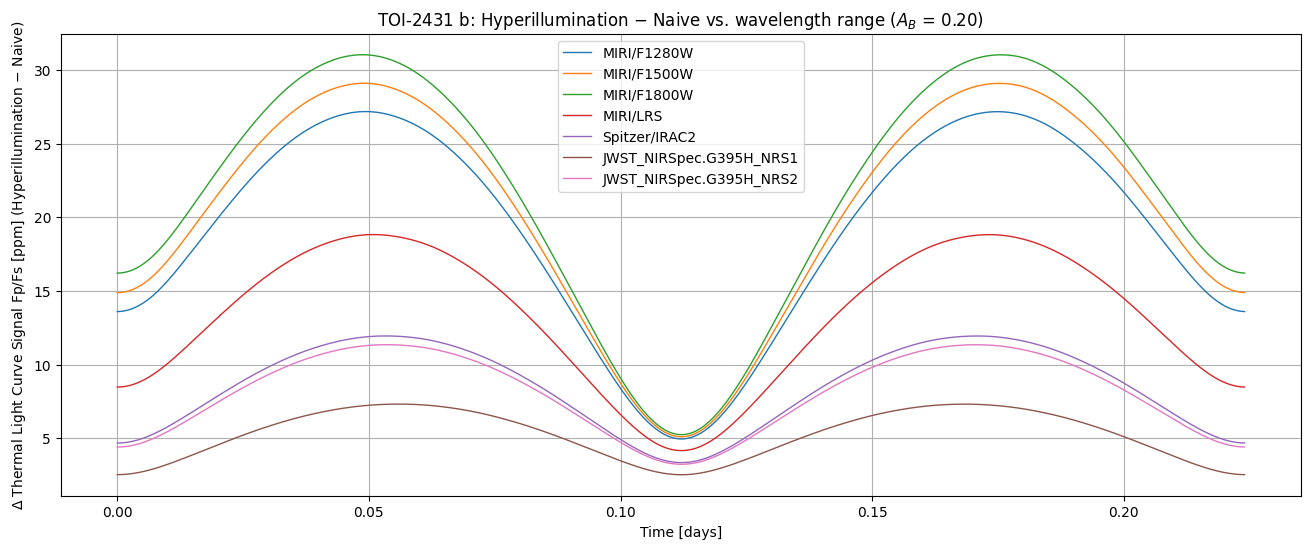

In [21]:
PAPER_MODE = False
# lambda_range/filter_path values differ per band -> special-cased instead of using the generic helper
plt.figure(figsize=(16, 6))
for band_name in instruments():
    kwargs = dict(baseline_kwargs)
    kwargs["lambda_range"] = filter_lambda(band_name)
    kwargs["filter_path"] = filter_loc(band_name)
    t_k, lc_k, _, _ = thermal_PhaseCurve(planet, include_transit=False, include_occultation=False, insolation_model="hyperillum", **kwargs)
    _,   lc_n, _, _ = thermal_PhaseCurve(planet, include_transit=False, include_occultation=False, insolation_model="naive", **kwargs)
    plt.plot(t_k, (lc_k - lc_n)*1e6, linewidth=1, label=band_name)
plt.xlabel("Time [days]")
plt.ylabel(r"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm] (Hyperillumination $-$ Naive)")
plt.title(f"{planet.name}: Hyperillumination $-$ Naive vs. wavelength range ($A_B$ = {A_B:.2f})")
plt.legend()
plt.grid()
paper_figure(f"thermal_hi_minus_naive_vs_band_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

#### Bolometric stellar limb darkening $u_B$

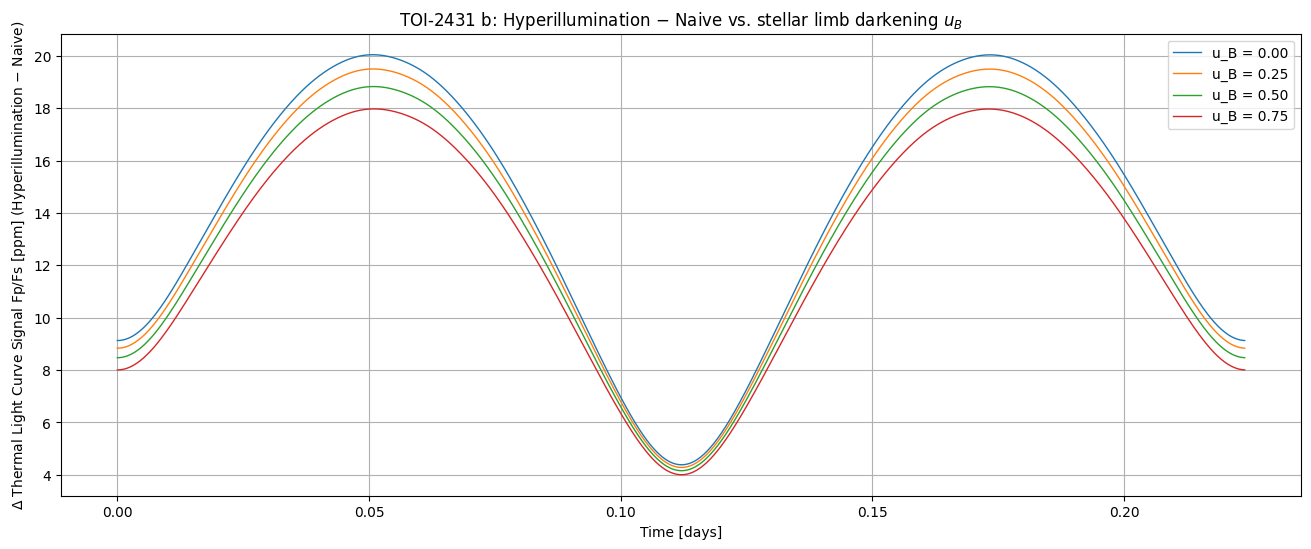

In [22]:
factors = np.array([0.0, 0.5, 1.0, 1.5])  # multiples of the baseline u_B
sweep_hyperillumination_minus_naive("u_B", u_B*factors, lambda v: f"u_B = {v:.2f}", "stellar limb darkening $u_B$", **baseline_kwargs)

#### Stellar effective temperature $T_\mathrm{eff}$

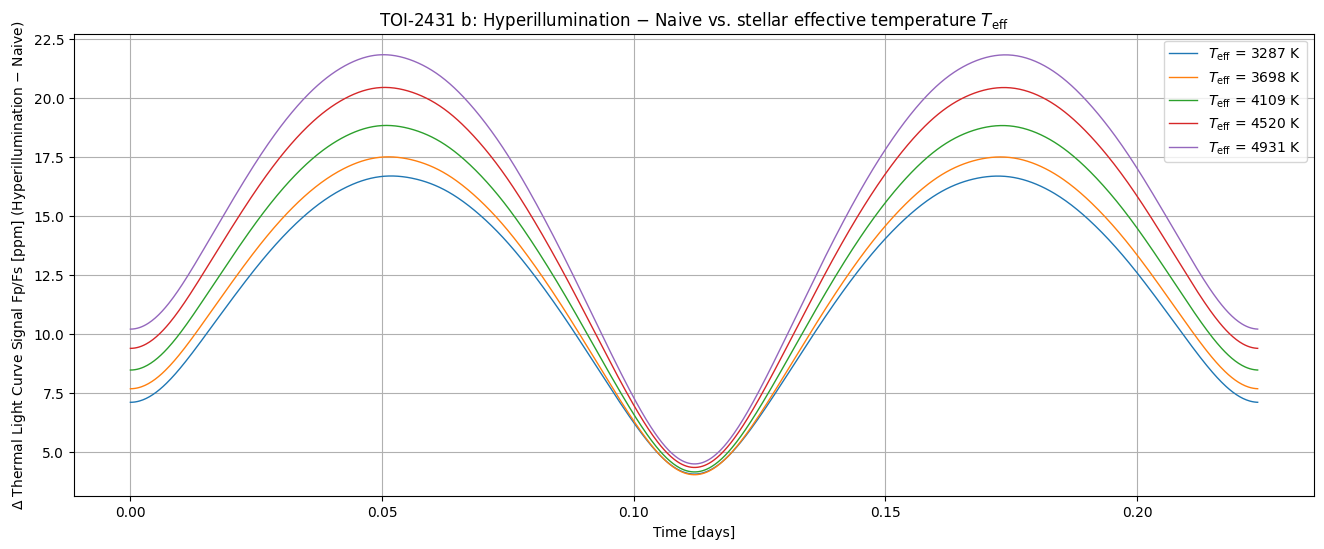

In [23]:
factors = np.array([0.8, 0.9, 1.0, 1.1, 1.2])  # +/- 20% around each K2-141b baseline value

sweep_hyperillumination_minus_naive("T2_eff", T_eff*factors, lambda v: f"$T_\\mathrm{{eff}}$ = {v:.0f} K", "stellar effective temperature $T_\\mathrm{eff}$", **baseline_kwargs)

#### Planet radius / Stellar radius $r_p$

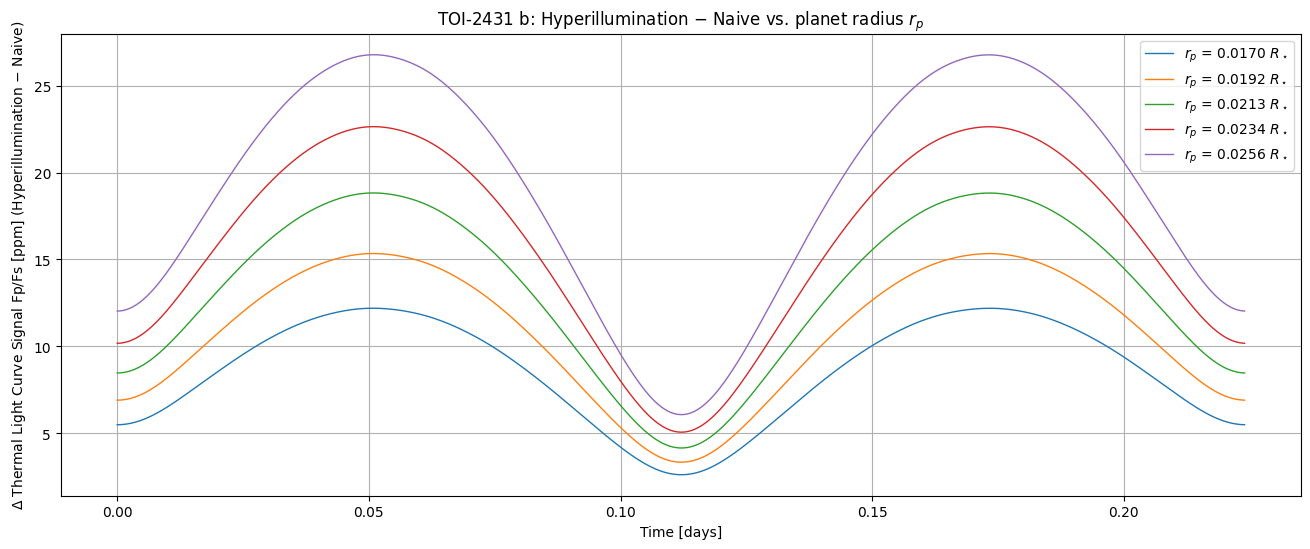

In [24]:
sweep_hyperillumination_minus_naive("r1", rp*factors, lambda v: f"$r_p$ = {v:.4f} $R_\\star$", "planet radius $r_p$", **baseline_kwargs)

#### Semi-major axis / Stellar radius $a$

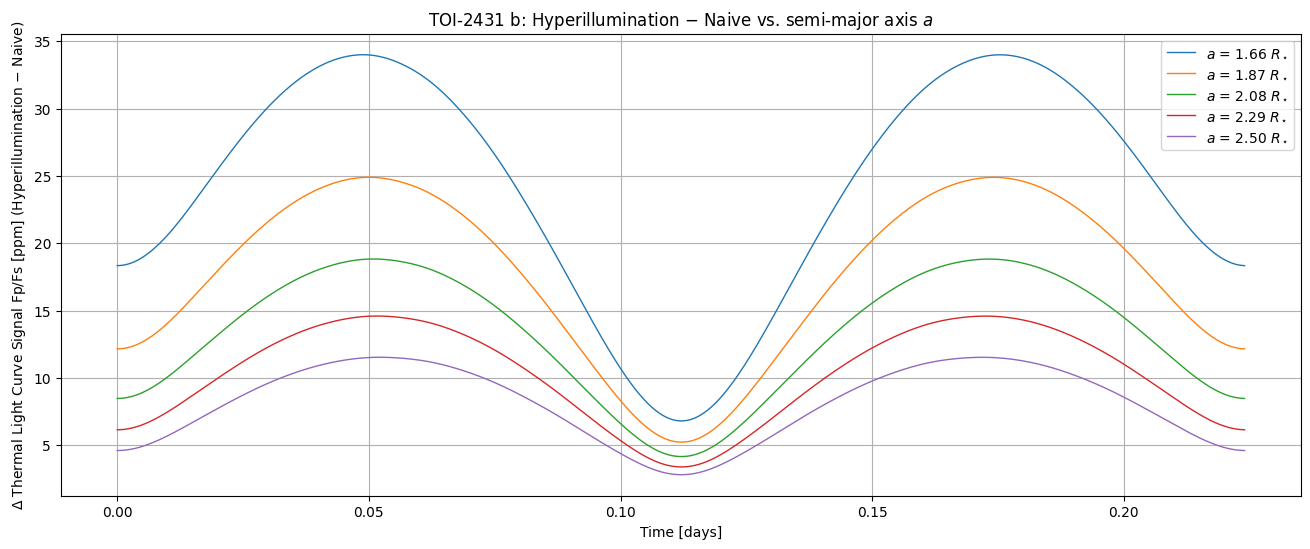

In [25]:
sweep_hyperillumination_minus_naive( "R", a*factors, lambda v: f"$a$ = {v:.2f} $R_\\star$", "semi-major axis $a$", **baseline_kwargs)

#### Orbital period

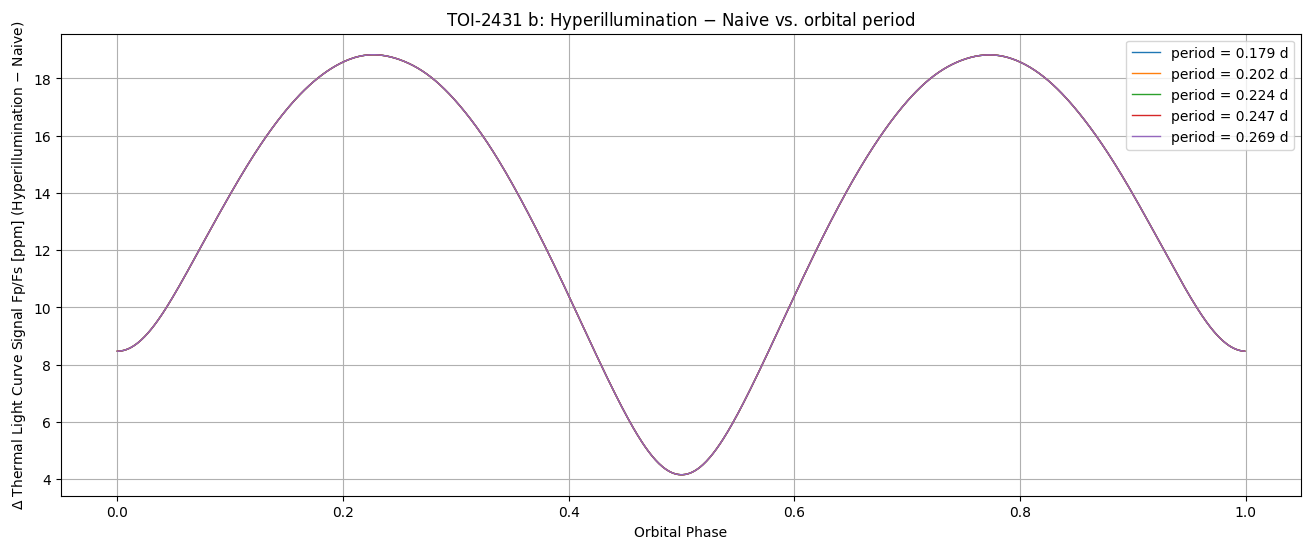

In [26]:
sweep_hyperillumination_minus_naive("period", period*factors, lambda v: f"period = {v:.3f} d", "orbital period", **baseline_kwargs)